In [61]:
import pandas as pd
csv_df = pd.read_csv("student_habits.csv")
excel_df = pd.read_excel("student_habits.xlsx", sheet_name="Data")
json_df = pd.read_json("student_habits.json", orient="records")
tsv_df = pd.read_csv("student_habits.tsv", sep="\t")
for name, frame in [("CSV", csv_df), ("Excel", excel_df),
                    ("JSON", json_df), ("TSV", tsv_df)]:
    print(name, frame.shape, frame.columns.tolist())
df = csv_df.copy()


CSV (62, 6) ['student_id', 'study_hours', 'attendance_percent', 'previous_score', 'internet_access', 'preferred_mode']
Excel (62, 6) ['student_id', 'study_hours', 'attendance_percent', 'previous_score', 'internet_access', 'preferred_mode']
JSON (62, 6) ['student_id', 'study_hours', 'attendance_percent', 'previous_score', 'internet_access', 'preferred_mode']
TSV (62, 6) ['student_id', 'study_hours', 'attendance_percent', 'previous_score', 'internet_access', 'preferred_mode']


In [62]:
df.head()

,student_id,study_hours,attendance_percent,previous_score,internet_access,preferred_mode
0,1001,2.0,97.0,64.0,no,Online
1,1002,12.0,90.0,77.0,Yes,In person
2,1003,unknown,75.0,76.0,YES,Online
3,1004,7.0,99.0,66.0,No,In person
4,1005,7.0,76.0,87.0,YES,In person


In [63]:
print(df.shape)

(62, 6)


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          62 non-null     int64  
 1   study_hours         61 non-null     object 
 2   attendance_percent  61 non-null     float64
 3   previous_score      61 non-null     float64
 4   internet_access     62 non-null     object 
 5   preferred_mode      62 non-null     object 
dtypes: float64(2), int64(1), object(3)
memory usage: 3.0+ KB


In [65]:
# Show duplicate rows in the dataset
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

# Show missing values per column
missing_values = df.isnull().sum()
print("\nMissing values per column:")
print(missing_values)

Total duplicate rows: 2

Missing values per column:
student_id            0
study_hours           1
attendance_percent    1
previous_score        1
internet_access       0
preferred_mode        0
dtype: int64


In [66]:
raw_df = df
df = df.drop_duplicates()
missing_values = df.isnull().sum()
print("\nMissing values per column:")
print(missing_values)


Missing values per column:
student_id            0
study_hours           1
attendance_percent    1
previous_score        1
internet_access       0
preferred_mode        0
dtype: int64


In [67]:
# Calculate the number of rows that contain at least one missing value
missing_rows_count = df.isnull().any(axis=1).sum()
print(f"Number of rows with at least one missing value: {missing_rows_count}")

# Display those specific rows to see which values are missing
print("\nRows containing missing values:")
display(df[df.isnull().any(axis=1)])

Number of rows with at least one missing value: 3

Rows containing missing values:


,student_id,study_hours,attendance_percent,previous_score,internet_access,preferred_mode
5,1006,NaN,73.0,71.0,YES,Online
12,1013,12.0,NaN,45.0,No,Online
15,1016,12.0,79.0,NaN,Yes,Online


In [68]:
# Convert columns to numeric
for col in ['study_hours', 'attendance_percent', 'previous_score']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Display the top rows to see the effect on 'unknown'
print("Columns converted successfully. Here is the head of the DataFrame:")
display(df.head())

# Explanation
print("\nExplanation:\nUsing errors='coerce' forces any non-numeric value (such as the string 'unknown' in row index 2) to be converted to NaN (Not a Number), representing a missing value.")

Columns converted successfully. Here is the head of the DataFrame:


/tmp/ipykernel_1001/498430854.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = pd.to_numeric(df[col], errors='coerce')


,student_id,study_hours,attendance_percent,previous_score,internet_access,preferred_mode
0,1001,2.0,97.0,64.0,no,Online
1,1002,12.0,90.0,77.0,Yes,In person
2,1003,NaN,75.0,76.0,YES,Online
3,1004,7.0,99.0,66.0,No,In person
4,1005,7.0,76.0,87.0,YES,In person



Explanation:
Using errors='coerce' forces any non-numeric value (such as the string 'unknown' in row index 2) to be converted to NaN (Not a Number), representing a missing value.


In [69]:
for val in df['study_hours']:
    if val < 0 or val > 40:
      print(val)
      df['study_hours'] = df['study_hours'].replace(val, None)
for val in df['attendance_percent']:
  if val < 0 or val > 100:
    print(val)
    df['attendance_percent'] = df['attendance_percent'].replace(val, None)





80.0
130.0


/tmp/ipykernel_1001/337068226.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['study_hours'] = df['study_hours'].replace(val, None)
/tmp/ipykernel_1001/337068226.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['attendance_percent'] = df['attendance_percent'].replace(val, None)


In [70]:
print(df.isnull().sum())

student_id            0
study_hours           3
attendance_percent    2
previous_score        1
internet_access       0
preferred_mode        0
dtype: int64


In [71]:
# Identify numeric columns
numeric_cols = ['study_hours', 'attendance_percent', 'previous_score']

# Count missing values before filling
missing_before = df[numeric_cols].isnull().sum()

# Fill missing values in each column with its median
for col in numeric_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# Count missing values after filling
missing_after = df[numeric_cols].isnull().sum()

# Calculate how many values were filled
filled_counts = missing_before - missing_after

print("Missing values filled per column:")
for col in numeric_cols:
    print(f"- {col}: {filled_counts[col]} values filled with median ({df[col].median()})")
print(f"\nTotal values filled: {filled_counts.sum()}")

Missing values filled per column:
- study_hours: 3 values filled with median (8.0)
- attendance_percent: 2 values filled with median (79.5)
- previous_score: 1 values filled with median (68.0)

Total values filled: 6


/tmp/ipykernel_1001/2959324511.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(median_value)
/tmp/ipykernel_1001/2959324511.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].fillna(median_value)
/tmp/ipykernel_1001/2959324511.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasti

In [72]:
df['preferred_mode'].unique()

array(['Online', 'In person', ' in person ', ' online '], dtype=object)

In [73]:
df['internet_access'].unique()

array([' no ', 'Yes', 'YES', 'No', ' yes '], dtype=object)

In [74]:
# Clean up whitespace in 'preferred_mode' and 'internet_access' columns
for col in ['preferred_mode', 'internet_access']:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.lower()

# Display unique values to verify
print("Unique preferred modes:", df['preferred_mode'].unique())
print("Unique internet access:", df['internet_access'].unique())

Unique preferred modes: ['online' 'in person']
Unique internet access: ['no' 'yes']


/tmp/ipykernel_1001/2193843735.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].str.strip()
/tmp/ipykernel_1001/2193843735.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].str.lower()


In [75]:
# Map 'yes' to 1 and 'no' to 0 in 'internet_access'
df['internet_access'] = df['internet_access'].map({'yes': 1, 'no': 0})

# Display the unique values and head of the DataFrame to verify
print("Unique values in internet_access:", df['internet_access'].unique())
display(df.head())

Unique values in internet_access: [0 1]


/tmp/ipykernel_1001/2060775383.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['internet_access'] = df['internet_access'].map({'yes': 1, 'no': 0})


,student_id,study_hours,attendance_percent,previous_score,internet_access,preferred_mode
0,1001,2.0,97.0,64.0,0,online
1,1002,12.0,90.0,77.0,1,in person
2,1003,8.0,75.0,76.0,1,online
3,1004,7.0,99.0,66.0,0,in person
4,1005,7.0,76.0,87.0,1,in person


In [77]:
# Generate dummy variables for 'preferred_mode'
df_dummies = pd.get_dummies(df['preferred_mode'], drop_first=True, dtype=int)



# Join the dummy column(s) back to the main DataFrame and drop the original text column
df = pd.concat([df.drop(columns=['preferred_mode']), df_dummies], axis=1)

# Display the columns and the first few rows to confirm
print("Current columns:", df.columns.tolist())
display(df.head())


Current columns: ['student_id', 'study_hours', 'attendance_percent', 'previous_score', 'internet_access', 'online']


,student_id,study_hours,attendance_percent,previous_score,internet_access,online
0,1001,2.0,97.0,64.0,0,1
1,1002,12.0,90.0,77.0,1,0
2,1003,8.0,75.0,76.0,1,1
3,1004,7.0,99.0,66.0,0,0
4,1005,7.0,76.0,87.0,1,0


In [80]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separate features and target
X = df.drop(columns=['student_id', 'previous_score'])
y = df['previous_score']

# 2. Split dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Create independent copies to ensure clean assignment
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 4. Fit the scaler on the training set and transform both train and test
scale_cols = ['study_hours', 'attendance_percent']
scaler = StandardScaler()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

# Display output to verify successful scaling
print(f"Train set shape: {X_train_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")
display(X_train_scaled.head())

Train set shape: (48, 4)
Test set shape: (12, 4)


,study_hours,attendance_percent,internet_access,online
31,-1.019727,0.981109,0,1
3,-0.270540,1.604861,0,0
52,-0.520269,0.090036,1,0
17,-1.519186,-1.068360,1,1
8,-0.020811,-1.603005,1,0


In [85]:
# 1. COMPREHENSIVE RECHECK OF THE CLEANED DATAFRAME (Original Units)
print("=== FINAL CLEANED DATAFRAME RECHECK (df) ===")
print(f"Row Count: {len(df)}")
print(f"Missing values per column:\n{df.isnull().sum()}")
print(f"Duplicate row count: {df.duplicated().sum()}")
print(f"Study hours range (Original): [{df['study_hours'].min()}, {df['study_hours'].max()}]")
print(f"Attendance percent range (Original): [{df['attendance_percent'].min()}, {df['attendance_percent'].max()}]")
print(f"Internet access values: {df['internet_access'].unique()}")
print(f"Online dummy values: {df['online'].unique()}")

# 2. VERIFY SCALED TRAINING FEATURES (Scaled Units)
print("\n=== PREPROCESSED TRAINING FEATURES RECHECK (X_train_scaled) ===")
print(f"Study hours range (Scaled): [{X_train_scaled['study_hours'].min():.4f}, {X_train_scaled['study_hours'].max():.4f}]")
print(f"Attendance percent range (Scaled): [{X_train_scaled['attendance_percent'].min():.4f}, {X_train_scaled['attendance_percent'].max():.4f}]")
print(f"Study hours Mean: {X_train_scaled['study_hours'].mean():.4f} (expected ~0), Std: {X_train_scaled['study_hours'].std():.4f} (expected ~1)")
print(f"Attendance Mean: {X_train_scaled['attendance_percent'].mean():.4f} (expected ~0), Std: {X_train_scaled['attendance_percent'].std():.4f} (expected ~1)")

# 3. EXPORT PROCESS
# Export the fully cleaned dataset
df.to_csv('student_habits_clean.csv', index=False)
print("\n'student_habits_clean.csv' exported successfully!")

# Export the preprocessed training feature set (scaled & encoded)
X_train_scaled.to_csv('student_habits_preprocessed.csv', index=False)
print("'student_habits_preprocessed.csv' (training features) exported successfully!")

=== FINAL CLEANED DATAFRAME RECHECK (df) ===
Row Count: 60
Missing values per column:
student_id            0
study_hours           0
attendance_percent    0
previous_score        0
internet_access       0
online                0
dtype: int64
Duplicate row count: 0
Study hours range (Original): [1.0, 15.0]
Attendance percent range (Original): [60.0, 99.0]
Internet access values: [0 1]
Online dummy values: [1 0]

=== PREPROCESSED TRAINING FEATURES RECHECK (X_train_scaled) ===
Study hours range (Scaled): [-1.7689, 1.7273]
Attendance percent range (Scaled): [-1.8703, 1.6049]
Study hours Mean: -0.0000 (expected ~0), Std: 1.0106 (expected ~1)
Attendance Mean: 0.0000 (expected ~0), Std: 1.0106 (expected ~1)

'student_habits_clean.csv' exported successfully!
'student_habits_preprocessed.csv' (training features) exported successfully!


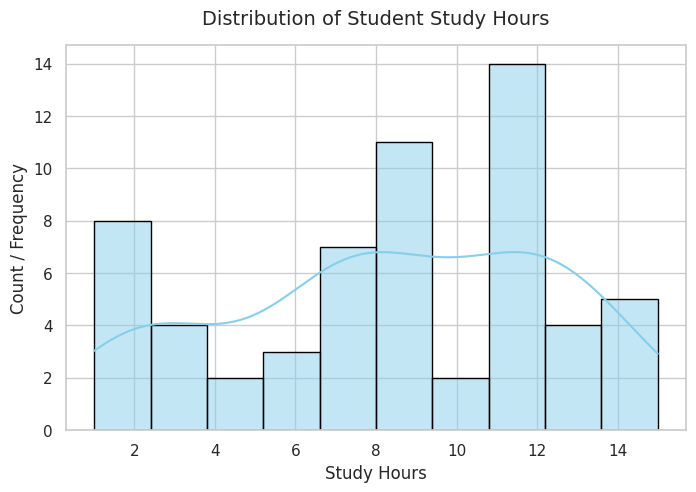

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plot style
sns.set_theme(style="whitegrid")

# Create the histogram for study hours
plt.figure(figsize=(8, 5))
sns.histplot(df['study_hours'], bins=10, kde=True, color='skyblue', edgecolor='black')

# Add labels and title
plt.title('Distribution of Student Study Hours', fontsize=14, pad=15)
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Count / Frequency', fontsize=12)

# Show the plot
plt.show()

/tmp/ipykernel_1001/3846760187.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=plot_df, x='preferred_mode', palette='Set2')


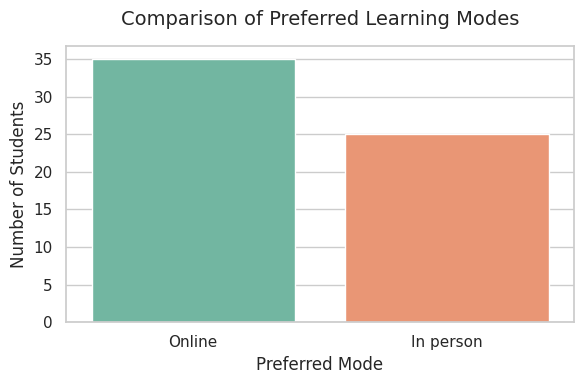

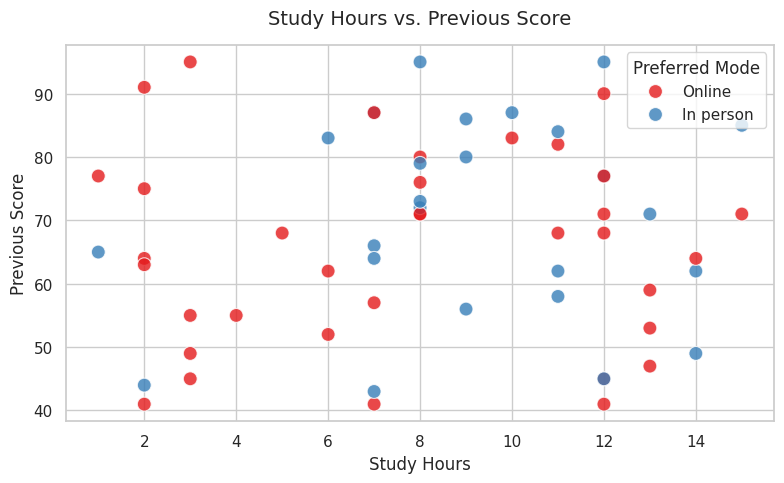

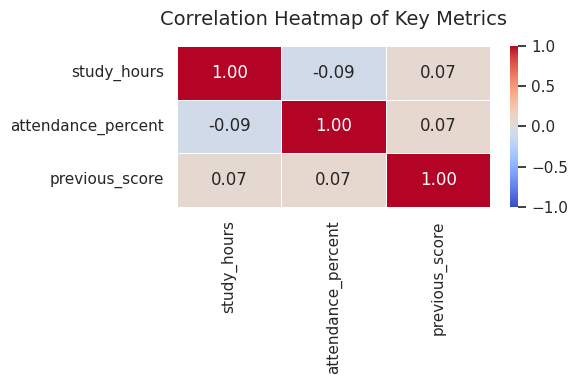

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set the plotting style
sns.set_theme(style="whitegrid")

# Create a temporary DataFrame to restore 'preferred_mode' label for visualization
plot_df = df.copy()
plot_df['preferred_mode'] = plot_df['online'].map({1: 'Online', 0: 'In person'})

# 2. Count plot of preferred_mode
plt.figure(figsize=(6, 4))
sns.countplot(data=plot_df, x='preferred_mode', palette='Set2')
plt.title('Comparison of Preferred Learning Modes', fontsize=14, pad=15)
plt.xlabel('Preferred Mode', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Scatter plot of study_hours vs previous_score colored by preferred_mode
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df,
    x='study_hours',
    y='previous_score',
    hue='preferred_mode',
    palette='Set1',
    s=100,
    alpha=0.8
)
plt.title('Study Hours vs. Previous Score', fontsize=14, pad=15)
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Previous Score', fontsize=12)
plt.legend(title='Preferred Mode')
plt.tight_layout()
plt.show()

# 4. Correlation heatmap (exclude student_id and categorical/encoded columns)
plt.figure(figsize=(6, 4))
num_cols = ['study_hours', 'attendance_percent', 'previous_score']
corr_matrix = plot_df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Key Metrics', fontsize=14, pad=15)
plt.tight_layout()
plt.show()